# 02 — Représentations du texte : TF-IDF et embeddings

Comment transformer un énoncé (et sa solution Python) en vecteur exploitable par un classifieur ?

1. **TF-IDF** : principe, choix de prétraitement, mots appris par une régression logistique.
2. **TF-IDF par tag** : quels mots et quels tokens de code caractérisent chaque tag ?
3. **Embeddings Sentence-BERT** (`all-mpnet-base-v2`) : structure de l'espace (BERTopic, UMAP).
4. **Comparaison en validation croisée** : TF-IDF vs Sentence-BERT avec le même classifieur linéaire.

**Entrée** : `data/processed/clean.parquet` (notebook 01). **Sortie** : cache des embeddings de la description.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from bertopic import BERTopic
from hdbscan import HDBSCAN
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from sentence_transformers import SentenceTransformer
from sklearn.base import clone
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from umap import UMAP

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 140)

/Users/ramzi/Documents/illuin-test/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1117 21:58:21.954000 69252 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## Paramètres

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks_prod" else Path.cwd()
DATA_PATH = ROOT / "data" / "processed" / "clean.parquet"
EMBEDDINGS_DIR = ROOT / "data" / "embeddings"

TAGS = ["math", "graphs", "strings", "number theory", "trees", "geometry", "games", "probabilities"]
SEED = 42
N_FOLDS = 5

TEXT_MODEL = "sentence-transformers/all-mpnet-base-v2"
DESC_MIN_DF = 10  # un mot doit apparaître dans au moins 10 énoncés pour devenir une colonne TF-IDF
CODE_MIN_DF = 5

# Tokens du code : identifiants d'au moins 2 caractères et nombres d'au moins 2 chiffres (ex. 998244353)
CODE_TOKEN_PATTERN = r"[A-Za-z_][A-Za-z0-9_]+|\d{2,}"
# Mots-clés Python et entrées/sorties : présents dans toutes les solutions, sans lien avec le tag
CODE_STOP_WORDS = [
    "False", "None", "True", "and", "as", "assert", "async", "await", "break", "class", "continue", "def", "del",
    "elif", "else", "except", "finally", "for", "from", "global", "if", "import", "in", "is", "lambda", "nonlocal",
    "not", "or", "pass", "raise", "return", "try", "while", "with", "yield",
    "sys", "stdin", "stdout", "readline", "input", "raw_input", "print", "write", "flush", "os", "io", "self",
]  # fmt: skip

## Données

In [3]:
df = pd.read_parquet(DATA_PATH)
Y = np.array([[tag in tags for tag in TAGS] for tags in df["tags"]], dtype=int)
is_train = (df["split"] == "train").to_numpy()
is_dev = (df["split"] != "test").to_numpy()  # train + val : sert à la validation croisée, le test reste de côté

train_df, Y_train = df[is_train], Y[is_train]
print(f"{len(df)} exercices | " + ", ".join(f"{s}={n}" for s, n in df["split"].value_counts().items()))

4834 exercices | train=3383, test=726, val=725


## 1. Comprendre la TF-IDF

La TF-IDF donne à un mot $t$ dans un document $d$ un poids élevé s'il est fréquent dans $d$ mais rare dans le corpus :

$$\text{TF-IDF}(t, d) = \big(1 + \log \text{count}(t, d)\big) \times \Big(\log\frac{1 + N}{1 + \text{df}(t)} + 1\Big)$$

Trois choix sur ce dataset :
1. **TF sous-linéaire** (`sublinear_tf=True`) : un mot répété 50 fois ne pèse pas 50 fois plus.
2. **Description lemmatisée, code brut** : la lemmatisation regroupe *vertex / vertices* ; dans le code, on garde la
   casse et on retire les mots-clés Python et les tokens d'entrée/sortie, communs à toutes les solutions.
3. **Pas de fuite** : le vocabulaire et l'IDF sont appris sur le train uniquement.

In [4]:
desc_vectorizer = TfidfVectorizer(stop_words="english", min_df=DESC_MIN_DF, sublinear_tf=True)
X_desc = desc_vectorizer.fit_transform(train_df["text_lemma"])

code_vectorizer = TfidfVectorizer(
    token_pattern=CODE_TOKEN_PATTERN, lowercase=False, stop_words=CODE_STOP_WORDS, min_df=CODE_MIN_DF, sublinear_tf=True
)
X_code = code_vectorizer.fit_transform(train_df["source_code"])

pd.DataFrame(
    {
        "vocabulaire (colonnes)": [X_desc.shape[1], X_code.shape[1]],
        "termes actifs par exemple": [X_desc.getnnz(axis=1).mean(), X_code.getnnz(axis=1).mean()],
        "valeurs nulles (%)": [100 * (1 - X.nnz / np.prod(X.shape)) for X in (X_desc, X_code)],
    },
    index=["description (lemmatisée)", "code (tokens)"],
).round(2)

,vocabulaire (colonnes),termes actifs par exemple,valeurs nulles (%)
description (lemmatisée),1812,33.88,98.13
code (tokens),1671,20.22,98.79


In [5]:
idf = pd.Series(desc_vectorizer.idf_, index=desc_vectorizer.get_feature_names_out()).sort_values()
print("Termes les plus courants (IDF minimale) :", idf.head(8).round(2).to_dict())
print("Termes les plus rares (IDF maximale)     :", idf.tail(8).round(2).to_dict())

Termes les plus courants (IDF minimale) : {'number': 1.45, 'ha': 1.75, 'given': 1.82, 'integer': 1.88, 'want': 2.15, 'possible': 2.21, 'time': 2.24, 'example': 2.31}
Termes les plus rares (IDF maximale)     : {'preparation': 6.73, 'iahub': 6.73, 'activity': 6.73, 'consisted': 6.73, 'currency': 6.73, 'entry': 6.73, 'rotating': 6.73, 'forgotten': 6.73}


**Interprétabilité** : une régression logistique sur la TF-IDF apprend un poids par mot et par tag. Les mots aux poids
les plus forts montrent ce que le modèle a appris.

In [6]:
logreg = OneVsRestClassifier(LogisticRegression(class_weight="balanced", max_iter=2000))
logreg.fit(X_desc, Y_train)

words = desc_vectorizer.get_feature_names_out()
top_words = {}
for tag, estimator in zip(TAGS, logreg.estimators_):
    best = np.argsort(estimator.coef_[0])[::-1][:6]
    top_words[tag] = [f"{words[i]} ({estimator.coef_[0][i]:+.1f})" for i in best]
pd.DataFrame(top_words, index=pd.RangeIndex(1, 7, name="rang"))

,math,graphs,strings,number theory,trees,geometry,games,probabilities
rang,,,,,,,,
1,divisible (+2.5),road (+4.0),string (+8.6),divisor (+6.0),tree (+8.0),point (+7.2),turn (+6.2),probability (+10.0)
2,sum (+2.5),graph (+3.9),letter (+4.4),prime (+5.2),vertex (+4.1),plane (+5.1),player (+5.9),expected (+6.3)
3,frac (+2.3),connected (+3.6),word (+4.0),gcd (+4.1),connected (+4.0),angle (+4.8),optimally (+5.1),randomly (+4.0)
4,cdot (+2.1),edge (+3.1),oplus (+2.6),divisible (+3.6),node (+3.9),coordinate (+3.4),win (+4.7),equiprobably (+3.9)
5,number (+2.1),vertex (+3.0),english (+2.3),cdot (+3.5),path (+3.3),polygon (+3.1),play (+4.0),random (+3.6)
6,modulo (+2.0),city (+2.5),text (+2.2),integer (+3.0),road (+2.9),radius (+3.0),game (+4.0),calculate (+2.8)


## 2. TF-IDF par tag : quel vocabulaire caractérise chaque tag ?

On part cette fois des tags : on cherche les termes les plus **spécifiques** à chacun, plus un groupe de référence
« aucun tag cible ». Calculé sur le **train uniquement** (ces termes servent à la baseline regex du notebook 03).

**Version naïve** : concaténer les textes de chaque tag en un seul document, puis TF-IDF sur ces 9 documents. L'IDF
calculée sur 9 documents est presque plate, et des mots partout présents (*number*, *integer*) dominent.

**Version retenue** :

$$\text{score}(\text{terme}, \text{tag}) = \underbrace{\text{part des exercices du tag contenant le terme}}_{\text{présence binaire}} \times \underbrace{\log\frac{N}{\text{nb d'exercices contenant le terme}}}_{\text{IDF sur tous les exercices}}$$

La présence binaire évite qu'un template copié-collé compte 50 fois.

Version naïve (biaisée vers les mots fréquents) :


,math,graphs,strings,number theory,trees,geometry,games,probabilities,(aucun tag cible)
0,number,vertex,string,number,vertex,point,player,number,number
1,integer,number,letter,integer,tree,polygon,game,probability,ha
2,array,edge,number,array,node,coordinate,turn,integer,array
3,ha,road,character,given,number,ha,play,ha,integer
4,given,city,length,positive,edge,segment,number,value,time
5,operation,graph,substring,ha,ha,number,alice,node,th


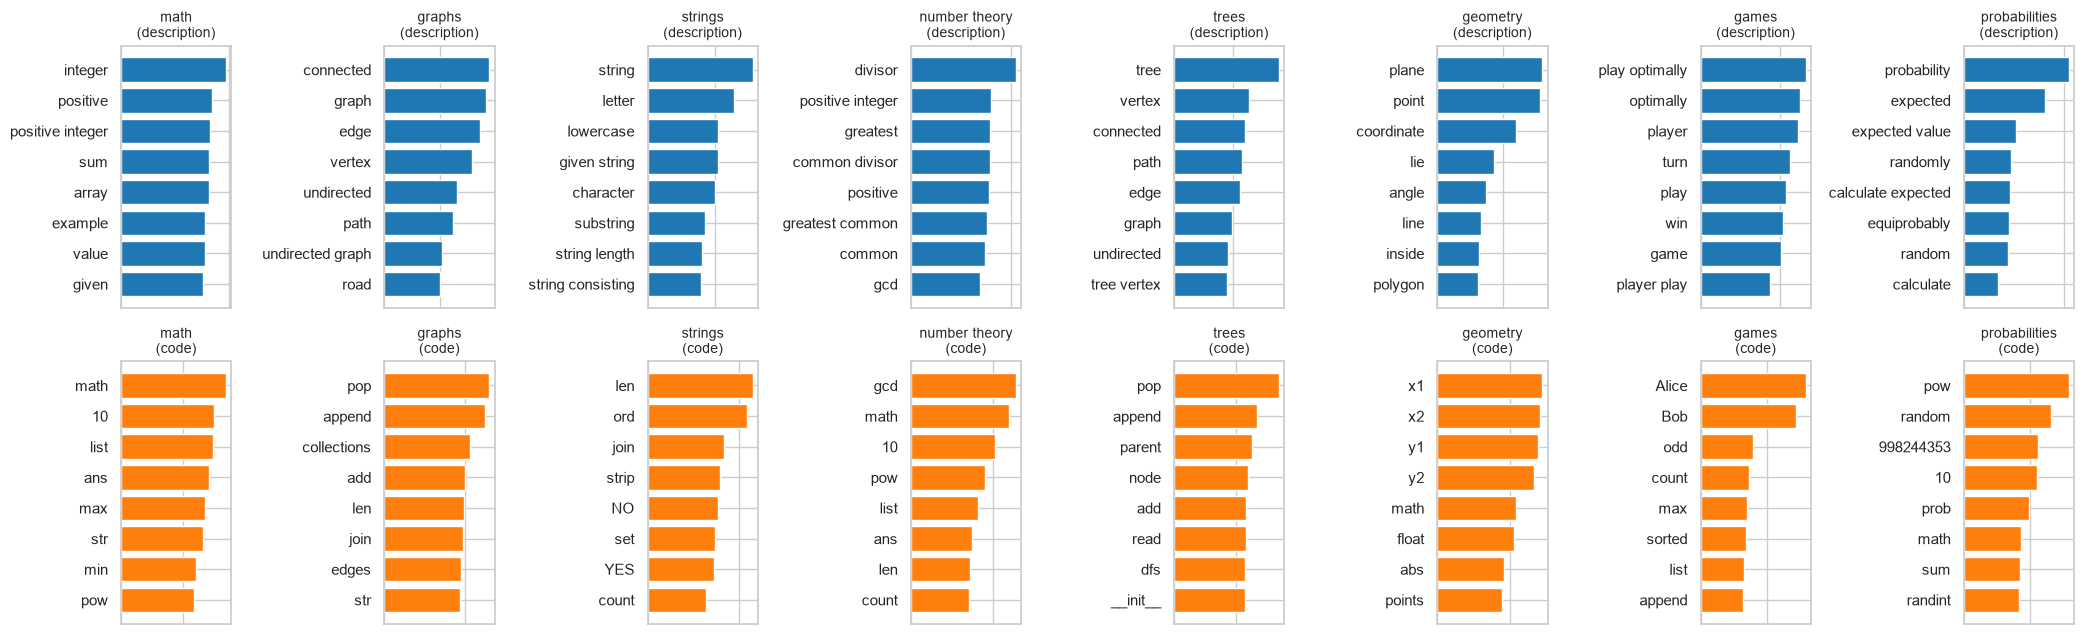

In [7]:
NO_TAG = "(aucun tag cible)"
groups = {tag: Y_train[:, k] == 1 for k, tag in enumerate(TAGS)}
groups[NO_TAG] = Y_train.sum(axis=1) == 0


def naive_tag_tfidf(texts: pd.Series) -> pd.DataFrame:
    """TF-IDF classique sur 9 « documents de tag » (textes concaténés)."""
    docs = [" ".join(texts[mask]) for mask in groups.values()]
    vectorizer = TfidfVectorizer(stop_words="english")
    scores = vectorizer.fit_transform(docs).toarray()
    return pd.DataFrame(scores, index=list(groups), columns=vectorizer.get_feature_names_out())


def tag_tfidf(texts: pd.Series, **vectorizer_args) -> pd.DataFrame:
    """Score (tag x terme) = part des exercices du tag contenant le terme × IDF globale."""
    vectorizer = CountVectorizer(min_df=5, binary=True, **vectorizer_args)
    presence = vectorizer.fit_transform(texts)
    idf = np.log(presence.shape[0] / presence.sum(axis=0).A1)
    scores = {name: presence[mask].mean(axis=0).A1 * idf for name, mask in groups.items()}
    return pd.DataFrame(scores, index=vectorizer.get_feature_names_out()).T


def top_terms(scores: pd.DataFrame, n: int = 6) -> pd.DataFrame:
    return pd.DataFrame({tag: row.nlargest(n).index.tolist() for tag, row in scores.iterrows()})


print("Version naïve (biaisée vers les mots fréquents) :")
display(top_terms(naive_tag_tfidf(train_df["text_lemma"])))

desc_scores = tag_tfidf(train_df["text_lemma"], stop_words="english", ngram_range=(1, 2))
code_scores = tag_tfidf(train_df["source_code"], token_pattern=CODE_TOKEN_PATTERN, lowercase=False, stop_words=CODE_STOP_WORDS)

fig, axes = plt.subplots(2, len(TAGS), figsize=(21, 6.5))
for row, (source, scores) in enumerate({"description": desc_scores, "code": code_scores}.items()):
    for ax, tag in zip(axes[row], TAGS):
        top = scores.loc[tag].nlargest(8)[::-1]
        ax.barh(top.index, top.values, color="tab:blue" if row == 0 else "tab:orange")
        ax.set_title(f"{tag}\n({source})", fontsize=10)
        ax.tick_params(axis="x", labelbottom=False)
plt.tight_layout()
plt.show()

**Lecture**
- 7 tags sur 8 ont des marqueurs nets dans l'énoncé (`strings` → *letter* ; `games` → *play optimally* ;
  `geometry` → *point, polygon* ; `probabilities` → *probability, expected*).
- **`math` fait exception** dans l'énoncé (termes génériques), mais **le code le trahit** (`gcd`, `pow`), comme
  `probabilities` (`998244353`) ou `games` (`Alice`, `Bob`) : le code est une source à exploiter.
- `graphs` et `trees` partagent les tokens de parcours (`append`, `pop`, `deque`) : cohérent avec leurs co-occurrences.

## 3. Embeddings denses (Sentence-BERT)

La TF-IDF traite chaque mot comme une colonne indépendante : elle ne rapproche pas *chance* et *probability*, et ne
comprend pas une phrase. Un encodeur **Sentence-BERT** transforme un texte entier en un vecteur de 768 dimensions où
deux textes de sens proche sont proches.

Les embeddings sont longs à calculer (~1 min 30 pour 4 834 textes) : on les met en cache sur disque.

In [8]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"


def cached_embeddings(texts: pd.Series, model_name: str, cache_name: str, batch_size: int = 32, max_len: int | None = None) -> np.ndarray:
    """Embeddings normalisés L2 ; relus depuis le cache s'il correspond aux mêmes exemples et au même modèle."""
    path = EMBEDDINGS_DIR / f"{model_name.split('/')[-1]}__{cache_name}.npz"
    if path.exists():
        cache = np.load(path)
        if str(cache["model"]) == model_name and np.array_equal(cache["sample_id"], texts.index):
            return cache["embeddings"]

    encoder = SentenceTransformer(model_name, device=device)
    if max_len:
        encoder.max_seq_length = max_len
    embeddings = encoder.encode(texts.tolist(), batch_size=batch_size, normalize_embeddings=True, show_progress_bar=True)
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez(path, embeddings=embeddings, sample_id=texts.index.to_numpy(), model=model_name)
    return embeddings


E_desc = cached_embeddings(df["text_clean"], TEXT_MODEL, "prob_desc_description")
print("Embeddings de la description :", E_desc.shape)

Embeddings de la description : (4834, 768)


In [9]:
# Troncature et vitesse d'encodage
encoder = SentenceTransformer(TEXT_MODEL, device=device)
n_tokens = pd.Series([len(ids) for ids in encoder.tokenizer(df["text_clean"].tolist())["input_ids"]])
print(f"device={device} | longueur max={encoder.max_seq_length} tokens | dimension={encoder.get_sentence_embedding_dimension()}")
print(f"Textes tronqués : {(n_tokens > encoder.max_seq_length).mean():.1%} (médiane {n_tokens.median():.0f} tokens)")

sample = df["text_clean"].sample(256, random_state=SEED).tolist()
encoder.encode(sample[:32])  # échauffement
start = time.perf_counter()
encoder.encode(sample, batch_size=32)
print(f"Vitesse : {(time.perf_counter() - start) / len(sample) * 1000:.1f} ms par texte")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17780.43it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (396 > 384). Running this sequence through the model will result in indexing errors


device=mps | longueur max=384 tokens | dimension=768
Textes tronqués : 2.9% (médiane 173 tokens)


Vitesse : 17.0 ms par texte


**Structure de l'espace** : BERTopic regroupe les énoncés proches (réduction UMAP en 5 dimensions puis clustering
HDBSCAN), sans utiliser les tags. On regarde ensuite si les groupes trouvés correspondent aux tags.
Le *lift* d'un tag dans un groupe = sa fréquence dans le groupe / sa fréquence globale (> 1 : sur-représenté).

61 groupes | exemples hors groupe : 35.1%


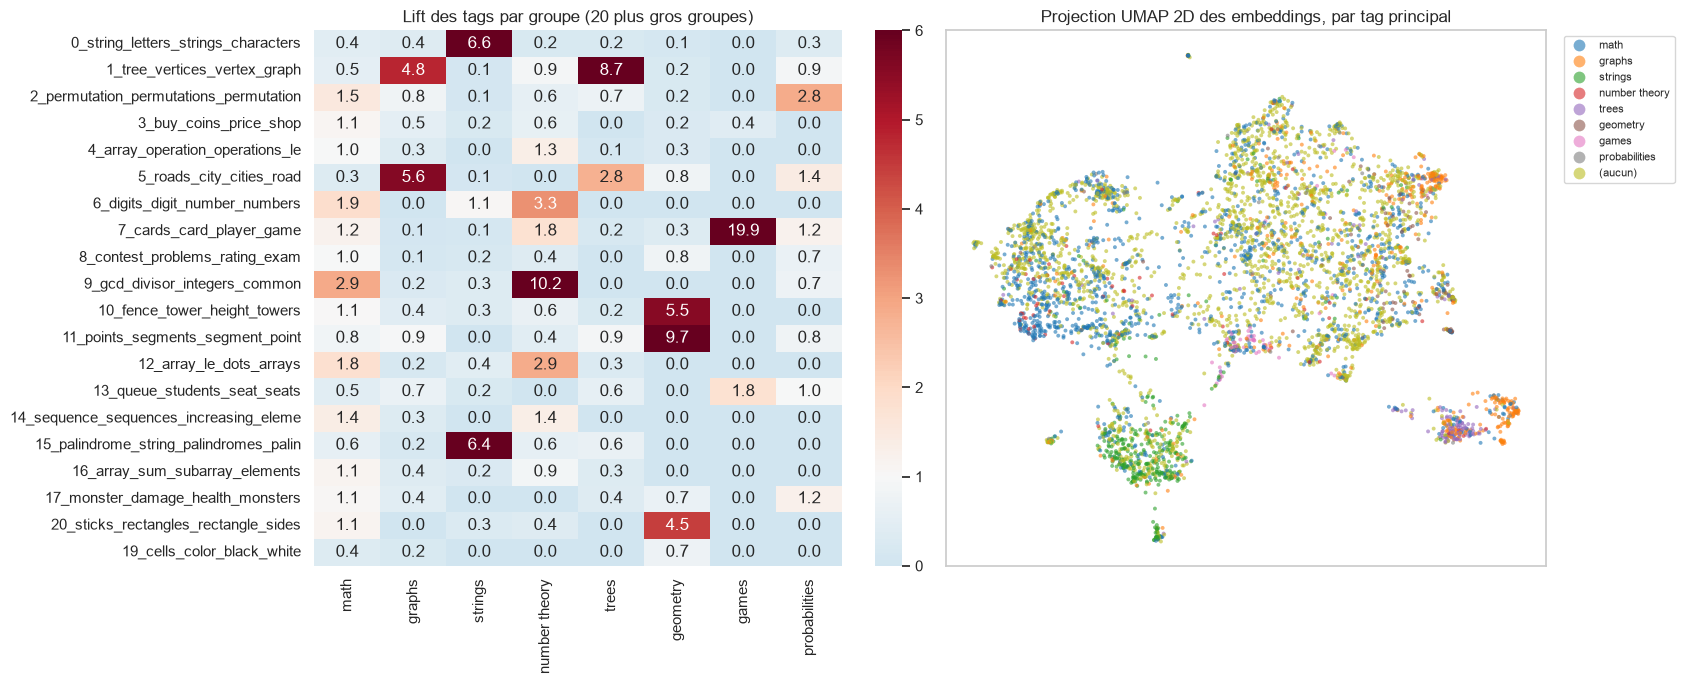

In [10]:
topic_model = BERTopic(
    umap_model=UMAP(n_neighbors=15, n_components=5, metric="cosine", random_state=SEED),
    hdbscan_model=HDBSCAN(min_cluster_size=15, min_samples=5, prediction_data=True),
    vectorizer_model=CountVectorizer(stop_words="english", min_df=2, ngram_range=(1, 2)),
)
topics = np.array(topic_model.fit_transform(df["text_clean"].tolist(), E_desc)[0])
clustered = topics != -1
print(f"{len(set(topics[clustered]))} groupes | exemples hors groupe : {(~clustered).mean():.1%}")

Y_df = pd.DataFrame(Y, columns=TAGS)
lift = Y_df[clustered].groupby(topics[clustered]).mean() / Y_df.mean()
biggest = pd.Series(topics[clustered]).value_counts().head(20).index
names = [topic_model.get_topic_info(t)["Name"].iloc[0][:38] for t in biggest]

fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(lift.loc[biggest].set_axis(names), cmap="RdBu_r", center=1, vmax=6, annot=True, fmt=".1f", ax=axes[0])
axes[0].set(title="Lift des tags par groupe (20 plus gros groupes)")

coords = UMAP(n_neighbors=15, n_components=2, metric="cosine", random_state=SEED).fit_transform(E_desc)
main_tag = Y_df.idxmax(axis=1).where(Y_df.sum(axis=1) > 0, "(aucun)")
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=main_tag, hue_order=TAGS + ["(aucun)"], palette="tab10", s=8, alpha=0.6, linewidth=0, ax=axes[1])
axes[1].set(title="Projection UMAP 2D des embeddings, par tag principal", xticks=[], yticks=[])
axes[1].legend(markerscale=3, bbox_to_anchor=(1.02, 1), fontsize=8)
plt.tight_layout()
plt.show()

## 4. TF-IDF vs Sentence-BERT en validation croisée

Même classifieur pour toutes les représentations : **8 régressions logistiques** (une par tag, `class_weight="balanced"`).

**Protocole** : validation croisée 5 folds sur train + val, stratifiée multi-label. Critère : **Macro-AP** (aire sous
la courbe précision-rappel, moyennée sur les 8 tags). Elle ne dépend pas d'un seuil de décision, ce qui permet de
comparer des modèles avant d'avoir réglé leurs seuils. Pour la TF-IDF, le vectoriseur fait partie du pipeline :
il est réappris dans chaque fold, sur les données d'entraînement du fold uniquement.

In [11]:
folds = list(MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(is_dev.sum()), Y[is_dev]))


def cross_val_macro_ap(model, X, Y) -> tuple[float, float]:
    """Macro-AP moyenne et écart-type sur les folds ; `clone` repart d'un modèle vierge à chaque fold."""
    scores = []
    for train_idx, eval_idx in folds:
        fitted = clone(model).fit(X[train_idx], Y[train_idx])
        scores.append(average_precision_score(Y[eval_idx], fitted.predict_proba(X[eval_idx]), average="macro"))
    return np.mean(scores), np.std(scores)


def logistic(C: float = 1.0) -> OneVsRestClassifier:
    return OneVsRestClassifier(LogisticRegression(C=C, class_weight="balanced", max_iter=2000))


Y_dev = Y[is_dev]
desc_dev = df.loc[is_dev, "text_lemma"].to_numpy()
code_dev = df.loc[is_dev, "source_code"].to_numpy()

# Régularisation C : plus C est petit, plus les poids sont contraints
rows = []
for C in (0.1, 0.3, 1.0, 3.0, 10.0):
    desc_model = make_pipeline(TfidfVectorizer(stop_words="english", min_df=DESC_MIN_DF, sublinear_tf=True), logistic(C))
    code_model = make_pipeline(
        TfidfVectorizer(token_pattern=CODE_TOKEN_PATTERN, lowercase=False, stop_words=CODE_STOP_WORDS, min_df=CODE_MIN_DF, sublinear_tf=True),
        logistic(C),
    )
    rows.append({"C": C, "TF-IDF description": cross_val_macro_ap(desc_model, desc_dev, Y_dev)[0], "TF-IDF code": cross_val_macro_ap(code_model, code_dev, Y_dev)[0]})
tfidf_cv = pd.DataFrame(rows).set_index("C")
tfidf_cv.round(4)

,TF-IDF description,TF-IDF code
C,,
0.1,0.5662,0.3174
0.3,0.5770,0.3191
1.0,0.5815,0.3122
3.0,0.5761,0.2993
10.0,0.5605,0.2813


,cv_macro_ap
TF-IDF code (C=0.3),0.3191
TF-IDF description (C=1),0.5815
Sentence-BERT description (C=1),0.5903


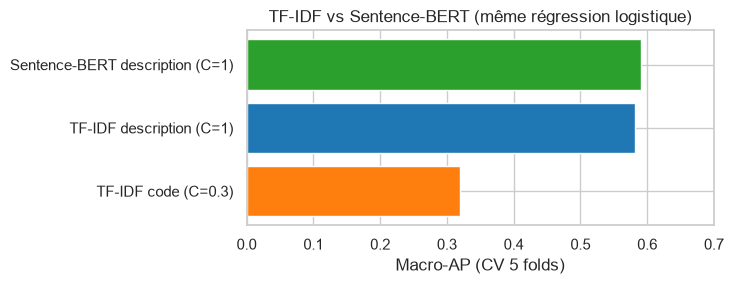

In [12]:
best_C = tfidf_cv.idxmax()
sbert_mean, sbert_std = cross_val_macro_ap(logistic(), E_desc[is_dev], Y_dev)

summary = pd.DataFrame(
    {
        f"TF-IDF code (C={best_C['TF-IDF code']:g})": tfidf_cv["TF-IDF code"].max(),
        f"TF-IDF description (C={best_C['TF-IDF description']:g})": tfidf_cv["TF-IDF description"].max(),
        "Sentence-BERT description (C=1)": sbert_mean,
    },
    index=["cv_macro_ap"],
).T
display(summary.round(4))

fig, ax = plt.subplots(figsize=(7.5, 3))
ax.barh(summary.index, summary["cv_macro_ap"], color=["tab:orange", "tab:blue", "tab:green"])
ax.set(xlim=(0, 0.7), xlabel="Macro-AP (CV 5 folds)", title="TF-IDF vs Sentence-BERT (même régression logistique)")
plt.tight_layout()
plt.show()

## Constats

- **La TF-IDF de description fait presque jeu égal avec Sentence-BERT** (≈ 0,58 vs 0,59 de Macro-AP) : le vocabulaire
  précis (*play optimally*, *polygon*, *gcd*) est un signal fort.
- **BERTopic** forme des groupes cohérents pour les tags « narratifs » (`strings`, `trees`, `games`, `geometry`) mais
  laisse un tiers d'exemples hors groupe et ne capte ni `math` ni `probabilities` : un apprentissage supervisé est nécessaire.
- **La TF-IDF du code seul est faible** (≈ 0,32) : les noms de variables changent d'un auteur à l'autre. Un encodeur
  pré-entraîné sur du code (**UniXcoder**) sera testé au notebook 04.
- Les deux représentations de la description sont complémentaires : leur combinaison sera évaluée au notebook 04.